In [2]:
# Cell 1: Imports and Load Data
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score

# Load cleaned HOME CREDIT data
with open("../data/clean/hc_data.pkl", "rb") as f:
    X_train, X_test, y_train, y_test, feature_names = pickle.load(f)

print("Train shape:", X_train.shape)
print("Test shape:", X_test.shape)
print("Default in train:", y_train.sum())
print("Default in test:", y_test.sum())

Train shape: (246008, 79)
Test shape: (61503, 79)
Default in train: 19860
Default in test: 4965


In [3]:
# Cell 2: Train Random Forest
# Note: Using class_weight='balanced' because the dataset is highly imbalanced
rf_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=10,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)
print("Random Forest trained successfully!")

Random Forest trained successfully!


--- Classification Report ---
              precision    recall  f1-score   support

           0       0.96      0.74      0.83     56538
           1       0.17      0.61      0.26      4965

    accuracy                           0.73     61503
   macro avg       0.56      0.67      0.55     61503
weighted avg       0.89      0.73      0.79     61503

AUC-ROC: 0.7374947744330942


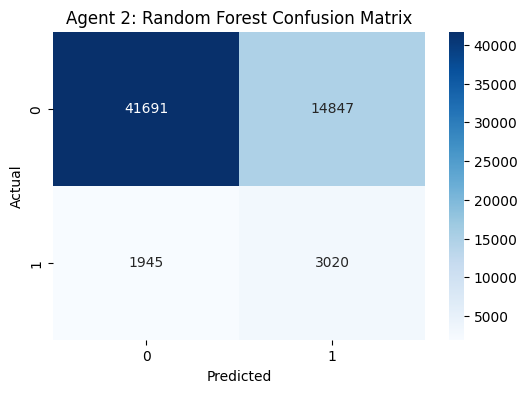

In [4]:
# Cell 3: Evaluate Model
y_pred_rf = rf_model.predict(X_test)
y_proba_rf = rf_model.predict_proba(X_test)[:, 1]

print("--- Classification Report ---")
print(classification_report(y_test, y_pred_rf))
print("AUC-ROC:", roc_auc_score(y_test, y_proba_rf))

# Plot Confusion Matrix
plt.figure(figsize=(6, 4))
cm = confusion_matrix(y_test, y_pred_rf)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.title('Agent 2: Random Forest Confusion Matrix')
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.show()

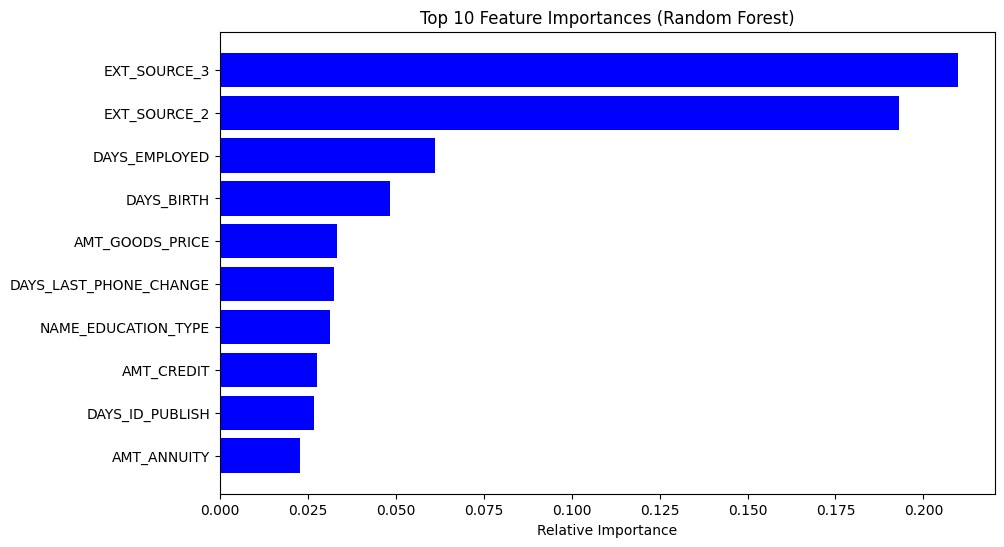

In [5]:
# Cell 4: Feature Importance (Optional but good for the report)
importances = rf_model.feature_importances_
indices = np.argsort(importances)[-10:]  # Top 10 features

plt.figure(figsize=(10, 6))
plt.title("Top 10 Feature Importances (Random Forest)")
plt.barh(range(len(indices)), importances[indices], color='b', align='center')
plt.yticks(range(len(indices)), [feature_names[i] for i in indices])
plt.xlabel("Relative Importance")
plt.show()

In [6]:
# Cell 5: Save the Model
import os
os.makedirs("../models", exist_ok=True)
with open("../models/agent2_rf.pkl", "wb") as f:
    pickle.dump(rf_model, f)
print("Saved Random Forest model!")

Saved Random Forest model!
